# Self-Organizing Map (SOM) Lab
**Name:** Muhammad Bilal  
**Reg no:** Fa23-bai-029

**Dataset:** Wine dataset (UCI Machine Learning Repository): 178 samples, 13 chemical features, 3 wine cultivars (classes). The labels are *not* used for training, only to evaluate the map afterwards.

## 1. Load and preprocess the data

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from collections import Counter

wine = load_wine()                      # UCI Wine dataset
X_raw, y = wine.data, wine.target
print("Shape:", X_raw.shape, "| Missing values:", np.isnan(X_raw).sum())

# Standardize: features have very different scales (e.g. proline ~1000, hue ~1).
# SOM uses Euclidean distance, so without scaling large features would dominate.
X = StandardScaler().fit_transform(X_raw)

Shape: (178, 13) | Missing values: 0


## 2. SOM implementation (from scratch, NumPy)

In [2]:
class SOM:
    def __init__(self, rows, cols, dim, lr0=0.5, sigma0=None, seed=42):
        self.rows, self.cols, self.lr0 = rows, cols, lr0
        self.sigma0 = sigma0 or max(rows, cols) / 2        # initial neighbourhood radius
        self.rng = np.random.default_rng(seed)
        self.W = self.rng.normal(size=(rows, cols, dim))   # random initial weight vectors
        # (row, col) coordinates of every neuron on the grid
        self.grid = np.dstack(np.meshgrid(np.arange(rows), np.arange(cols), indexing='ij'))

    def bmu(self, x):
        # Best Matching Unit = neuron whose weights are closest to x
        d = np.linalg.norm(self.W - x, axis=2)
        return np.unravel_index(np.argmin(d), d.shape)

    def quant_error(self, X):
        # Average distance between each sample and its BMU (lower = better fit)
        return np.mean([np.linalg.norm(x - self.W[self.bmu(x)]) for x in X])

    def topo_error(self, X):
        # Fraction of samples whose 1st and 2nd best neurons are NOT neighbours
        bad = 0
        for x in X:
            d = np.linalg.norm(self.W - x, axis=2).ravel()
            a, b = np.argsort(d)[:2]
            pa = np.unravel_index(a, (self.rows, self.cols))
            pb = np.unravel_index(b, (self.rows, self.cols))
            bad += max(abs(pa[0]-pb[0]), abs(pa[1]-pb[1])) > 1
        return bad / len(X)

    def train(self, X, epochs=50):
        T, t = epochs * len(X), 0
        self.qe, self.te = [], []
        for ep in range(epochs):
            for x in X[self.rng.permutation(len(X))]:       # shuffle each epoch
                lr    = self.lr0    * np.exp(-3 * t / T)    # learning rate decays
                sigma = self.sigma0 * np.exp(-3 * t / T)    # neighbourhood shrinks
                b = self.bmu(x)
                d2 = np.sum((self.grid - np.array(b))**2, axis=2)   # grid distance to BMU
                h = np.exp(-d2 / (2 * sigma**2))[..., None]         # Gaussian neighbourhood
                self.W += lr * h * (x - self.W)             # pull neurons toward x
                t += 1
            self.qe.append(self.quant_error(X))
            self.te.append(self.topo_error(X))
        return self

    def umatrix(self):
        # Mean distance of each neuron to its grid neighbours (high = cluster border)
        U = np.zeros((self.rows, self.cols))
        for i in range(self.rows):
            for j in range(self.cols):
                nb = [(i+di, j+dj) for di in (-1,0,1) for dj in (-1,0,1)
                      if (di or dj) and 0 <= i+di < self.rows and 0 <= j+dj < self.cols]
                U[i,j] = np.mean([np.linalg.norm(self.W[i,j]-self.W[n]) for n in nb])
        return U

## 3. Train the SOM

In [3]:
som = SOM(rows=8, cols=8, dim=X.shape[1], lr0=0.5)
print("Quantization error before training:", round(som.quant_error(X), 3))
som.train(X, epochs=50)
print("Quantization error after training :", round(som.qe[-1], 3))
print("Topographic error after training  :", round(som.te[-1], 3))

Quantization error before training: 3.057


Quantization error after training : 1.354
Topographic error after training  : 0.135


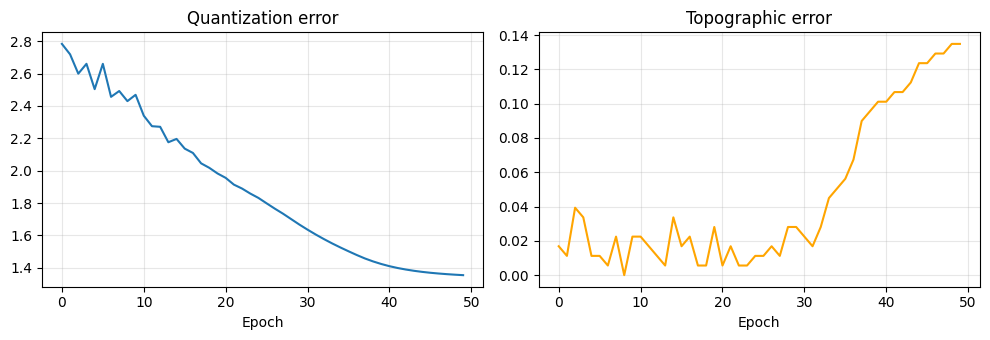

In [4]:
# Training curves
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(som.qe); ax[0].set_title('Quantization error'); ax[0].set_xlabel('Epoch')
ax[1].plot(som.te, c='orange'); ax[1].set_title('Topographic error'); ax[1].set_xlabel('Epoch')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Evaluate and visualize the map

Cluster purity: 0.983
Active neurons: 61 of 64


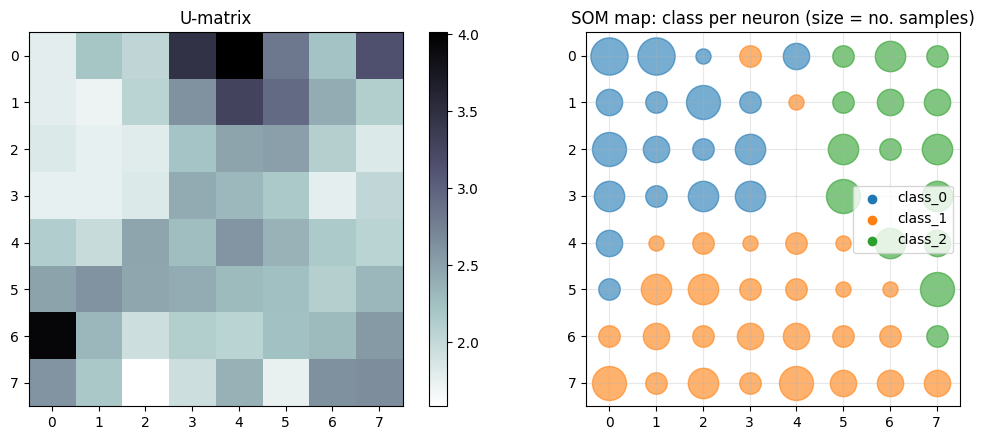

In [5]:
# Collect which samples land on which neuron
cells = {}
for x, lab in zip(X, y):
    cells.setdefault(som.bmu(x), []).append(lab)

# Purity: if each neuron is labelled with its majority class, how many samples are correct?
purity = sum(Counter(v).most_common(1)[0][1] for v in cells.values()) / len(y)
print(f"Cluster purity: {purity:.3f}")
print(f"Active neurons: {len(cells)} of {som.rows*som.cols}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# U-matrix: dark = similar neighbours (inside a cluster), bright = boundary between clusters
im = ax[0].imshow(som.umatrix(), cmap='bone_r'); ax[0].set_title('U-matrix')
plt.colorbar(im, ax=ax[0])

# Map with each neuron coloured by its majority class (sample count in the cell)
colors = ['tab:blue', 'tab:orange', 'tab:green']
ax[1].set_xlim(-0.5, som.cols-0.5); ax[1].set_ylim(som.rows-0.5, -0.5)
for (i, j), labs in cells.items():
    maj = Counter(labs).most_common(1)[0][0]
    ax[1].scatter(j, i, s=120*len(labs), c=colors[maj], alpha=0.6)
for k, name in enumerate(wine.target_names):
    ax[1].scatter([], [], c=colors[k], label=name)
ax[1].legend(); ax[1].set_title('SOM map: class per neuron (size = no. samples)')
ax[1].set_aspect('equal'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
# Report

## 1. Data preprocessing
- Loaded the UCI **Wine** dataset (178 samples, 13 numeric features, 3 classes). There were **no missing values**.
- Applied **standardization** (zero mean, unit variance) to every feature. Features such as *proline* (~1000) and *hue* (~1) have very different ranges, and the SOM uses Euclidean distance, so unscaled data would be dominated by proline.
- Class labels were **not** used in training (SOM is unsupervised); they were used only to judge the result.

## 2. Model architecture and hyperparameters
| Parameter | Value | Reason |
|---|---|---|
| Grid size | 8 × 8 (64 neurons) | Rule of thumb ≈ 5√N ≈ 67 neurons for N = 178; large enough to show structure, small enough that most neurons get data |
| Initial weights | Random normal | Matches the scale of standardized data |
| Initial learning rate | 0.5, exponentially decaying | Large steps first to organise the map, small steps later to fine-tune |
| Initial radius σ₀ | 4 (half the grid), exponentially decaying | Starts by moving the whole map together (global order), ends adjusting single neurons |
| Neighbourhood | Gaussian | Smooth update, keeps neighbouring neurons similar |
| Epochs | 50 (8,900 updates) | Errors flatten out by the end of training |

## 3. Training process and evaluation metrics
For each sample the SOM finds the Best Matching Unit (BMU), then moves the BMU and its grid neighbours toward the sample, with strength decreasing with distance and time. Metrics used:
- **Quantization error (QE):** average distance of a sample to its BMU. Fell from **3.06 (untrained map) → 1.35** after training.
- **Topographic error (TE):** share of samples whose two closest neurons are not adjacent on the grid (measures topology preservation). Final value: **0.135** (about 13.5%).
- **Cluster purity** (using labels only for evaluation): **0.983** (98.3%).
- **Active neurons:** 61 of 64 neurons had at least one sample.

## 4. Observations and insights
- The map **separated the three wine cultivars almost perfectly** without seeing labels (98.3% purity). Each class occupies its own region of the grid, as shown in the class map.
- The **U-matrix** shows brighter ridges between these regions (cluster borders) and darker areas inside them (similar samples).
- QE dropped steadily and flattened near the end, which shows the training converged.
- TE of about 13.5% means most neighbouring relationships are preserved, but some folding of the map occurs in 13-dimensional data squeezed onto a 2D grid, which is expected.
- Standardization was essential for good results. A larger grid or more epochs could lower QE further, but a bigger grid would leave more neurons empty with only 178 samples.